# Airline Passenger Satisfaction — Recommendation Prediction

Predict the reviewer's original **Yes/No recommendation** from seven service ratings (1–5). This is a post-flight feedback classifier, not a pre-flight forecast or a reconstruction of overall star ratings. Keep `airline_passenger_reviews.csv` beside this notebook.

Follow the supplied PDFs' data inspection, pipeline, validation and evaluation order. Required additions are Random Forest, chronological validation, balanced accuracy, baseline comparison and saving. Scaling is kept to match the PDF workflow, although Random Forest does not require it. Short comments appear in every code cell. Step 15 shows the measured test accuracy. The graphs in Steps 7a–7c follow the supplied plotting examples.

Source: [Skytrax reviews, Mendeley Data, version 1](https://data.mendeley.com/datasets/vgjk58vf8h/1), CC BY 4.0. The target is provided by reviewers and is not an official satisfaction survey measure. The dataset preparation and limits are documented in `PROJECT_GUIDE.md`.

**Current seven-rating model: test accuracy 95.13%; balanced test accuracy 94.67%.**

This is a user-requested extension evaluated on the same historical test period as the earlier six-rating model; it is not a fresh external validation.


In [1]:
#Step 1: Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import scatter_matrix
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import confusion_matrix, classification_report


In [2]:
#Step 2: Import dataset and create dataframe
dataset = pd.read_csv('airline_passenger_reviews.csv')
print(dataset.head())


   Seat_Comfort  ...                                          Review_ID
0           3.0  ...  189d37f9d4f9ea6fd5439b6f6bb84c25fb1707a47cf191...
1           5.0  ...  1d30e9216790630f47fc34489af593a48133cee20cb0e8...
2           5.0  ...  32c8799ae9872c4671cf3a3920457a7fda9e86a59374b8...
3           3.0  ...  3b19c04bb4b799796855033294c15efe13cdd7872ddb69...
4           1.0  ...  3f9f5d812fccf03a1d77845f72087d77356f6c2465f0ae...

[5 rows x 11 columns]


In [3]:
#Step 3: Get to know the data
print(dataset.shape)
dataset.info()


(64647, 11)
<class 'pandas.DataFrame'>
RangeIndex: 64647 entries, 0 to 64646
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Seat_Comfort            61181 non-null  float64
 1   Cabin_Staff_Service     60954 non-null  float64
 2   Food_and_Beverages      52066 non-null  float64
 3   Inflight_Entertainment  43499 non-null  float64
 4   Ground_Service          60033 non-null  float64
 5   Value_for_Money         64634 non-null  float64
 6   Wifi_Connectivity       23614 non-null  float64
 7   Recommended             64647 non-null  str    
 8   Review_Date             64647 non-null  str    
 9   Airline                 64647 non-null  str    
 10  Review_ID               64647 non-null  str    
dtypes: float64(7), str(4)
memory usage: 11.0 MB


In [4]:
#Step 4: Perform Data Preprocessing
print(dataset.isnull().sum())
print(dataset.describe())


Seat_Comfort               3466
Cabin_Staff_Service        3693
Food_and_Beverages        12581
Inflight_Entertainment    21148
Ground_Service             4614
Value_for_Money              13
Wifi_Connectivity         41033
Recommended                   0
Review_Date                   0
Airline                       0
Review_ID                     0
dtype: int64
       Seat_Comfort  Cabin_Staff_Service  ...  Value_for_Money  Wifi_Connectivity
count  61181.000000         60954.000000  ...     64634.000000       23614.000000
mean       2.839901             3.071857  ...         2.609184           2.207546
std        1.461721             1.592320  ...         1.602143           1.495852
min        1.000000             1.000000  ...         1.000000           1.000000
25%        1.000000             1.000000  ...         1.000000           1.000000
50%        3.000000             3.000000  ...         2.000000           1.000000
75%        4.000000             5.000000  ...         4.00000

In [5]:
#Step 5: Identify the features and target
#Overall rating, text, IDs and airline name are excluded from the inputs
features = ['Seat_Comfort', 'Cabin_Staff_Service', 'Food_and_Beverages',
            'Inflight_Entertainment', 'Ground_Service', 'Value_for_Money', 'Wifi_Connectivity']
X = dataset[features]
y = dataset['Recommended']
class_names = ['No', 'Yes']
print(X.head())


   Seat_Comfort  Cabin_Staff_Service  ...  Value_for_Money  Wifi_Connectivity
0           3.0                  4.0  ...              3.0                NaN
1           5.0                  5.0  ...              5.0                NaN
2           5.0                  4.0  ...              5.0                NaN
3           3.0                  3.0  ...              3.0                NaN
4           1.0                  1.0  ...              1.0                NaN

[5 rows x 7 columns]


In [6]:
#Step 6: Separate training and test data
#Keep later reviews for testing
train_mask = dataset['Review_Date'] < '2023-01-01'
test_mask = dataset['Review_Date'] >= '2023-01-01'
X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]
training_dates = dataset.loc[train_mask, 'Review_Date'].reset_index(drop=True)
print('Training records:', len(X_train))
print('Test records:', len(X_test))


Training records: 52833
Test records: 11814


In [7]:
#Step 7: Show the number of each class
print('Training support:')
print(y_train.value_counts())
print('Test support:')
print(y_test.value_counts())
print('Test percentages:')
print(y_test.value_counts(normalize=True) * 100)


Training support:
Recommended
No     31345
Yes    21488
Name: count, dtype: int64
Test support:
Recommended
No     8558
Yes    3256
Name: count, dtype: int64
Test percentages:
Recommended
No     72.439479
Yes    27.560521
Name: proportion, dtype: float64


Training-data graphs follow the PDF examples. Missing ratings are omitted; repeated 1–5 scores overlap in scatter plots. Wi-Fi is optional because many reviews do not rate it.

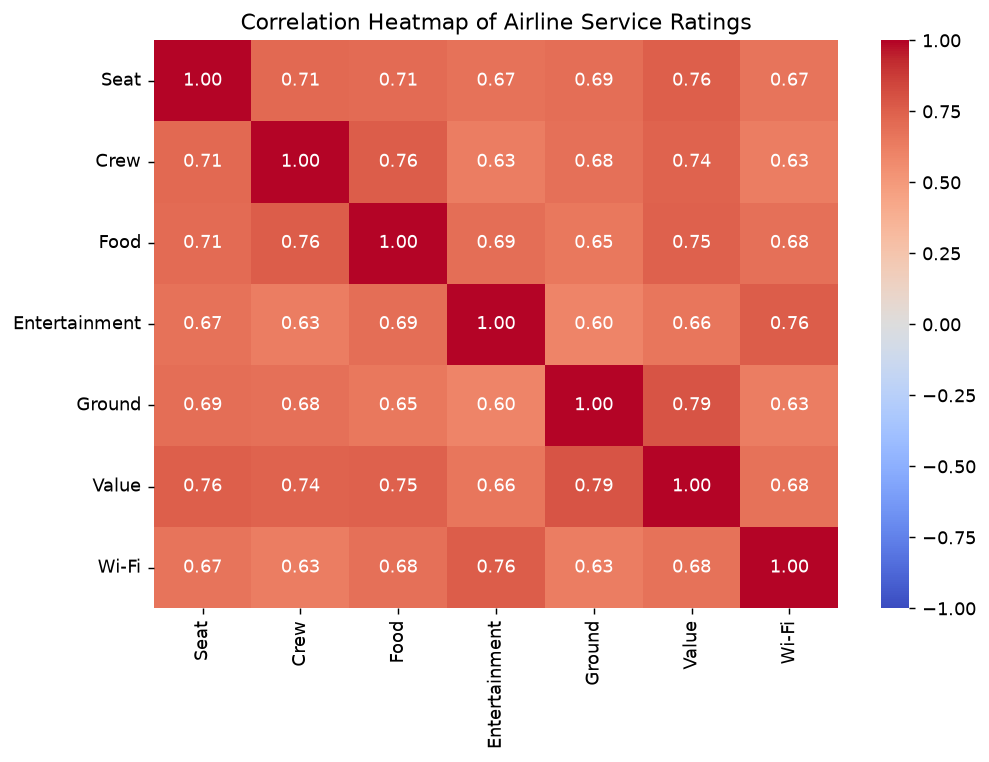

In [8]:
#Step 7a: Correlation Heatmap
graph_data = X_train.copy()
graph_data.columns = ['Seat', 'Crew', 'Food', 'Entertainment', 'Ground', 'Value', 'Wi-Fi']
corr_matrix = graph_data.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Airline Service Ratings')
plt.tight_layout()
plt.show()


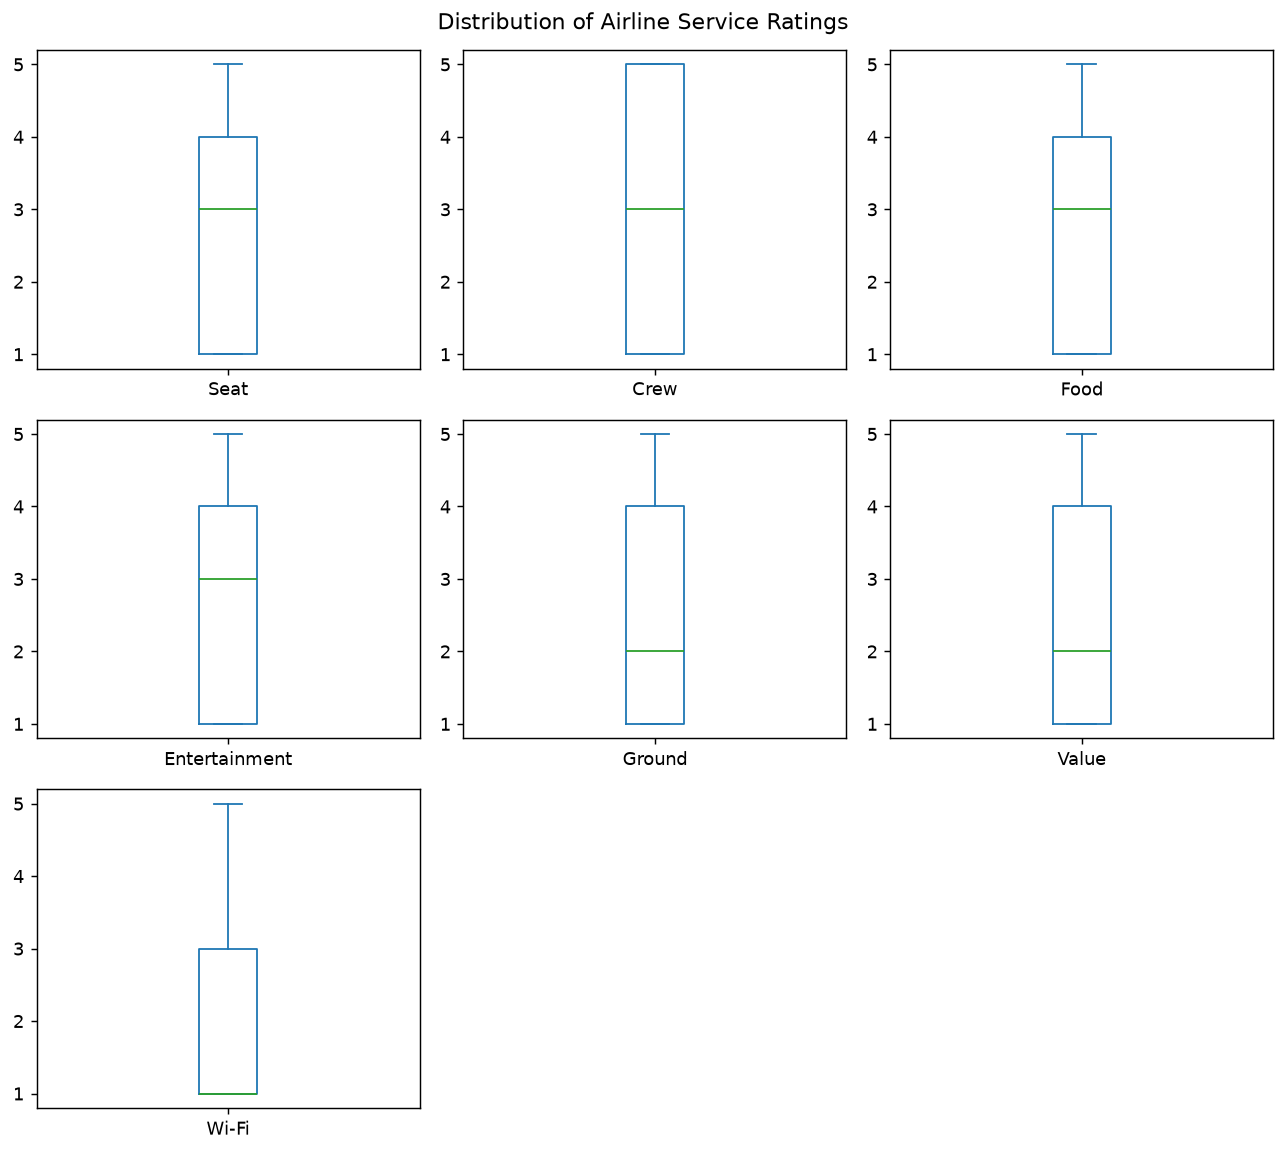

In [9]:
#Step 7b: Box and whisker plots
graph_data.plot(kind='box', subplots=True, layout=(3, 3),
                sharex=False, sharey=False, figsize=(10, 9))
plt.suptitle('Distribution of Airline Service Ratings')
plt.tight_layout()
plt.show()


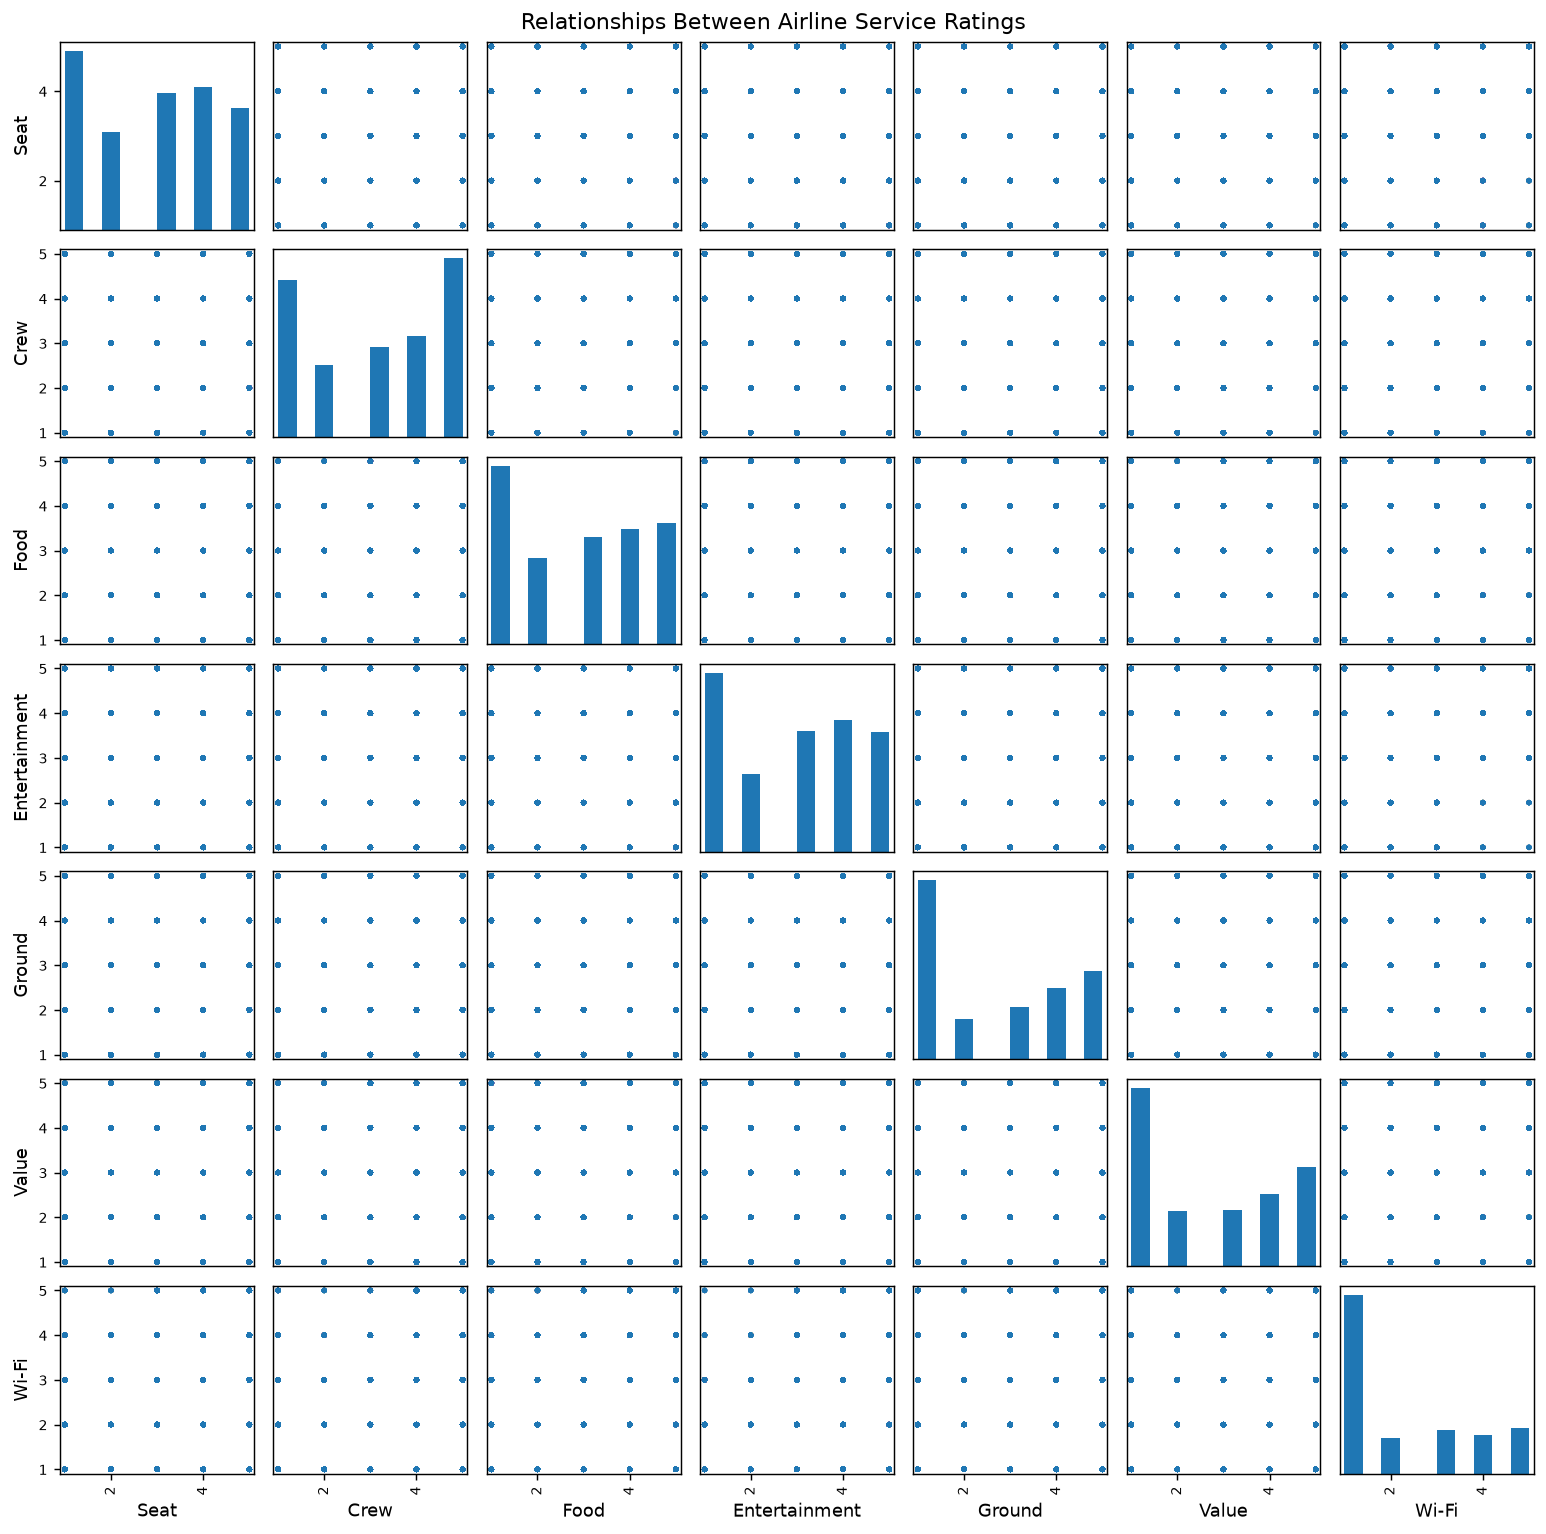

In [10]:
#Step 7c: Scatter plot matrix
scatter_matrix(graph_data, figsize=(12, 12), alpha=0.15)
plt.suptitle('Relationships Between Airline Service Ratings')
plt.tight_layout()
plt.show()


In [11]:
#Step 8: Apply pipeline
airlinePipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('std_scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight='balanced', n_jobs=4
    ))
])


In [12]:
#Step 9: Create cross-validation periods
#Every validation period follows its training period
periods = [('2019-01-01', '2021-01-01'),
           ('2021-01-01', '2022-01-01'),
           ('2022-01-01', '2023-01-01')]
cv = []
for start, end in periods:
    fit_rows = training_dates < start
    validation_rows = (training_dates >= start) & (training_dates < end)
    cv.append((training_dates.index[fit_rows], training_dates.index[validation_rows]))
print('Forward validation folds:', len(cv))


Forward validation folds: 3


In [13]:
#Step 10: Select Random Forest parameters
param_grid = {'classifier__max_depth':[8, 12, None],
              'classifier__min_samples_leaf':[5, 20]}
grid_search = GridSearchCV(
    airlinePipeline, param_grid, cv=cv, scoring='balanced_accuracy', n_jobs=1
)
grid_search.fit(X_train, y_train)
model = grid_search.best_estimator_
print('Best Parameters:', grid_search.best_params_)


Best Parameters: {'classifier__max_depth': 12, 'classifier__min_samples_leaf': 5}


In [14]:
#Step 11: Fit simple comparison models on training data
#Logistic Regression is taught in the PDFs
logisticPipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('std_scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced'))
])
logistic_search = GridSearchCV(
    logisticPipeline, {'classifier__C':[0.1, 1, 10]}, cv=cv,
    scoring='balanced_accuracy', n_jobs=1
)
logistic_search.fit(X_train, y_train)

#Choose an average-rating rule using only training validation folds
cutoffs = [1.5, 2, 2.5, 3, 3.5, 4, 4.5]
rule_scores = []
for cutoff in cutoffs:
    fold_scores = []
    for fit, validation in cv:
        imputer = SimpleImputer(strategy='median')
        imputer.fit(X_train.iloc[fit])
        average_rating = pd.Series(imputer.transform(X_train.iloc[validation]).mean(axis=1),
                                   index=y_train.iloc[validation].index)
        rule_pred = average_rating.ge(cutoff).map({True:'Yes', False:'No'})
        fold_scores.append(balanced_accuracy_score(y_train.iloc[validation], rule_pred))
    rule_scores.append(sum(fold_scores) / len(fold_scores))
rule_cutoff = cutoffs[rule_scores.index(max(rule_scores))]
rule_imputer = SimpleImputer(strategy='median').fit(X_train)
print('Selected average-rating cutoff:', rule_cutoff)


Selected average-rating cutoff: 3


In [15]:
#Step 12: Predict on test data
y_pred = model.predict(X_test)
print(pd.DataFrame({'Predicted':y_pred, 'Actual':y_test}).head(10))


      Predicted Actual
52833       Yes    Yes
52834        No     No
52835        No     No
52836        No     No
52837        No     No
52838       Yes     No
52839        No     No
52840        No     No
52841        No     No
52842        No     No


In [16]:
#Step 13: Cross-Validation Accuracy
best_index = grid_search.best_index_
cv_scores = [grid_search.cv_results_['split0_test_score'][best_index],
             grid_search.cv_results_['split1_test_score'][best_index],
             grid_search.cv_results_['split2_test_score'][best_index]]
print('Balanced Validation Accuracy per Fold (%):')
print(pd.Series(cv_scores) * 100)
print(f'Average Balanced Validation Accuracy: {grid_search.best_score_ * 100:.2f}%')


Balanced Validation Accuracy per Fold (%):
0    94.029834
1    94.594895
2    93.801765
dtype: float64
Average Balanced Validation Accuracy: 94.14%


In [17]:
#Step 14: Evaluate the model on training data
train_accuracy = accuracy_score(y_train, model.predict(X_train))
print(f'Model Accuracy on Training Data: {train_accuracy * 100:.2f}%')


Model Accuracy on Training Data: 94.73%


In [18]:
#Step 15: Evaluate the model on test data
test_accuracy = accuracy_score(y_test, y_pred)
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
print(f'TEST ACCURACY: {test_accuracy * 100:.2f}%')
print(f'BALANCED TEST ACCURACY: {balanced_accuracy * 100:.2f}%')


TEST ACCURACY: 95.13%
BALANCED TEST ACCURACY: 94.67%


In [19]:
#Step 16: Print Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=class_names)
print(pd.DataFrame(cm, index=class_names, columns=class_names))


       No   Yes
No   8190   368
Yes   207  3049


In [20]:
#Step 17: Print Classification report on test data
print(classification_report(y_test, y_pred, labels=class_names))


              precision    recall  f1-score   support

          No       0.98      0.96      0.97      8558
         Yes       0.89      0.94      0.91      3256

    accuracy                           0.95     11814
   macro avg       0.93      0.95      0.94     11814
weighted avg       0.95      0.95      0.95     11814



In [21]:
#Step 18: Compare test results with simple models
logistic_pred = logistic_search.best_estimator_.predict(X_test)
average_rating = pd.Series(rule_imputer.transform(X_test).mean(axis=1), index=y_test.index)
rule_pred = average_rating.ge(rule_cutoff).map({True:'Yes', False:'No'})
majority_class = y_train.mode()[0]
comparison = pd.DataFrame({
    'Model':['Random Forest', 'Logistic Regression', 'Average-rating rule', 'Majority class'],
    'Accuracy':[test_accuracy, accuracy_score(y_test, logistic_pred),
                accuracy_score(y_test, rule_pred), (y_test == majority_class).mean()],
    'Balanced Accuracy':[balanced_accuracy, balanced_accuracy_score(y_test, logistic_pred),
                         balanced_accuracy_score(y_test, rule_pred), 0.5]
})
print(comparison.to_string(index=False, float_format=lambda value:f'{value * 100:.2f}%'))


              Model  Accuracy  Balanced Accuracy
      Random Forest    95.13%             94.67%
Logistic Regression    94.83%             94.64%
Average-rating rule    93.52%             92.71%
     Majority class    72.44%             50.00%


In [22]:
#Step 19: Show feature importance
#Importance describes model use, not cause and effect
importance = pd.DataFrame({'Feature':features,
                           'Importance':model.named_steps['classifier'].feature_importances_})
print(importance.sort_values('Importance', ascending=False))


                  Feature  Importance
5         Value_for_Money    0.397127
1     Cabin_Staff_Service    0.185824
0            Seat_Comfort    0.179701
4          Ground_Service    0.145102
2      Food_and_Beverages    0.072618
3  Inflight_Entertainment    0.016193
6       Wifi_Connectivity    0.003436


In [23]:
#Step 20: Save the trained model
#Save the complete preprocessing and prediction pipeline
import pickle
with open('random_forest_model.pkl', 'wb') as model_file:
    pickle.dump(model, model_file)
print('Saved Random Forest pipeline')


Saved Random Forest pipeline
